# OmniBench: data pull and preproposal analysis

11-777 preproposal. This notebook downloads OmniBench, checks the data is what the paper says it is, and produces `omnibench_analysis.pdf` for the report.

Two panels come out of it:

1. **Composition** — how the 1,142 items split across task type and audio type. Determines which per-condition breakdowns we can actually report.
2. **Shortcut audit** — whether the correct option can be guessed from the question text alone. If it could, any efficiency saving we report might just be the model exploiting that, not genuinely compressing sensory input.

Every number in the writeup should be reproducible by running this top to bottom.

In [1]:
# Works on Colab and on Debian/Ubuntu Python (which refuses bare installs).
import sys, subprocess
pkgs = ["datasets", "matplotlib", "numpy", "nltk"]
cmd = [sys.executable, "-m", "pip", "install", "-q", *pkgs]
if subprocess.call(cmd) != 0:
    subprocess.check_call(cmd + ["--break-system-packages"])

# NLTK ships code and corpora separately; these are the corpora we need.
import nltk
for pkg in ["stopwords", "punkt", "punkt_tab", "wordnet"]:
    nltk.download(pkg, quiet=True)

print("dependencies ready")


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip


dependencies ready


## 1. Load the data

`m-a-p/OmniBench` on the Hub is the canonical copy and is what we use. It has one `train` split of 1,142 rows with the schema you see in the dataset viewer: the text fields, plus `audio` and `image` columns holding the actual media.

**Expect the first run to be slow.** `load_dataset` fetches the entire repo, media included, before any column is accessible. Dropping `audio` and `image` with `select_columns` saves the *decoding* cost (each row would otherwise become a numpy waveform and a PIL image), but it cannot save the *download*. You need that media eventually to run models, so it's not wasted, but budget several GB into `~/.cache/huggingface` and a few minutes.

If the Hub is unreachable or you just want the figure now, `SOURCE = "github"` pulls the same 1,142 records as a 2 MB JSONL with the media referenced by path instead of embedded. Both panels use only text fields, so the two sources give identical numbers. The cell falls back automatically if the Hub call fails.

In [2]:
SOURCE = "huggingface"   # "huggingface" (canonical, downloads media) or "github" (2 MB, text only)

import json, urllib.request

JSONL_URL = ("https://raw.githubusercontent.com/multimodal-art-projection/"
             "OmniBench/main/dataset/batch-5_1142_20240817.jsonl")

def load_from_hub():
    from datasets import load_dataset
    ds = load_dataset("m-a-p/OmniBench")
    print(ds)                      # confirm: one 'train' split, 1142 rows
    split = "train" if "train" in ds else list(ds.keys())[0]
    # Drop the media columns BEFORE iterating. Touching `audio` or `image`
    # decodes every row into a numpy waveform / PIL object, which is slow and
    # unnecessary here. This does not reduce the download, only the decode.
    keep = [c for c in ds[split].column_names if c not in ("audio", "image")]
    return [dict(r) for r in ds[split].select_columns(keep)]

def load_from_github():
    raw = urllib.request.urlopen(JSONL_URL).read().decode("utf-8")
    return [json.loads(line) for line in raw.splitlines() if line.strip()]

if SOURCE == "huggingface":
    try:
        records, used = load_from_hub(), "huggingface"
    except Exception as e:
        print(f"Hub load failed ({type(e).__name__}: {e})\nFalling back to GitHub JSONL.\n")
        records, used = load_from_github(), "github (fallback)"
else:
    records, used = load_from_github(), "github"

print(f"\nLoaded {len(records)} records from {used}")
print(f"Fields: {sorted(records[0].keys())}")

/opt/homebrew/lib/python3.11/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.3.0) or chardet (6.0.0dev0)/charset_normalizer (3.2.0) doesn't match a supported version!
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00003.parquet:   0%|          | 0.00/489M [00:00<?, ?B/s]

data/train-00001-of-00003.parquet:   0%|          | 0.00/394M [00:00<?, ?B/s]

data/train-00002-of-00003.parquet:   0%|          | 0.00/381M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1142 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['task type', 'audio type', 'question', 'audio content', 'image content', 'audio_path', 'image_path', 'index', 'answer', 'options', 'audio', 'image'],
        num_rows: 1142
    })
})

Loaded 1142 records from huggingface
Fields: ['answer', 'audio content', 'audio type', 'audio_path', 'image content', 'image_path', 'index', 'options', 'question', 'task type']


## 2. Look at one record

Before computing anything, read an actual item. The thing to notice: `audio content` is a **human transcript** and `image content` is a **VLM-generated caption**. Those are the text alternatives the paper uses for its ablations, and they are what makes our "maximally compressed encoding" condition possible without us having to build a captioner.

In [3]:
r = records[0]
for k in ["index", "task type", "audio type", "question", "options", "answer"]:
    print(f"{k:12s}: {r[k]}")
print(f"\naudio content: {r['audio content']}")
print(f"\nimage content: {r['image content'][:300]}...")

index       : 0
task type   : Action and Activity
audio type  : speech
question    : What are the men doing?
options     : ['The man in jeans is taking notes from the newspaper.', 'The man in purple is reading the newspaper.', 'The man in jeans is playing a crossword puzzle.', 'The man on the table is doing a crossword puzzle.']
answer      : The man in jeans is playing a crossword puzzle.

audio content: Two people talking: A: Four letters, "circle or hoop." B: Ring! Damn it, ring! A: Thanks.

image content: The image depicts a scene from a television show set in a cozy, well-furnished apartment. The main focus is on two individuals sitting on a couch in the foreground. The man on the left is wearing a dark blue jacket and jeans, and he is holding a newspaper and a pencil, seemingly engaged in a crosswo...


## 3. Sanity checks

Run these before trusting anything downstream. Each catches a specific way the analysis could be silently wrong.

- **Schema match.** Confirm the text fields are exactly the ones the dataset viewer advertises. If the Hub version ever gains or renames a column, this fails loudly instead of producing quietly wrong counts.
- **Answer in options.** The distractor computation is `[o for o in options if o != answer]`. If the answer string weren't among the options, that would return all four and compare the question against the correct answer twice.
- **Duplicate options.** The same expression drops *every* copy of a duplicated answer, so such an item contributes two distractors rather than three.
- **Task type count.** The repo README says 7. Check what the data actually contains.

In [4]:
from collections import Counter, defaultdict

EXPECTED = {"task type", "audio type", "question", "audio content", "image content",
            "audio_path", "image_path", "index", "answer", "options"}
got = set(records[0].keys()) - {"audio", "image"}
assert got == EXPECTED, f"schema drift: missing {EXPECTED-got}, unexpected {got-EXPECTED}"
print("schema matches the dataset viewer")

print("records:                    ", len(records))
print("options per item:           ", dict(Counter(len(r['options']) for r in records)))
print("answer missing from options:", sum(r['answer'] not in r['options'] for r in records))
print("items with duplicate opts:  ", sum(len(set(r['options'])) != 4 for r in records))
print("distinct task types:        ", len({r['task type'] for r in records}))
print("distinct audio types:       ", len({r['audio type'] for r in records}))
print("\naudio type counts:", dict(Counter(r['audio type'] for r in records)))

schema matches the dataset viewer
records:                     1142
options per item:            {4: 1142}
answer missing from options: 0
items with duplicate opts:   1
distinct task types:         8
distinct audio types:        3

audio type counts: {'speech': 771, 'sound event': 265, 'music': 106}


## 4. Panel 1 — composition

Straight counting, no derived quantities. Two things to look for, both of which constrain the experiments:

- Audio type is lopsided toward speech. Our hypothesis is that speech tolerates compression better than sound events, so we have the least data exactly where the effect should be largest.
- The task distribution has a long tail, with several near-empty cells. That rules out reporting a full task-by-audio grid.

In [5]:
grid = defaultdict(Counter)
for r in records:
    grid[r["task type"]][r["audio type"]] += 1

task_types = sorted(grid, key=lambda t: -sum(grid[t].values()))
audio_types = sorted({a for c in grid.values() for a in c})

for t in task_types:
    print(f"{t:42s} {sum(grid[t].values()):5d}  {dict(grid[t])}")

top5 = sum(sum(grid[t].values()) for t in task_types[:5])
print(f"\ntop 5 task types hold {top5} of {len(records)} items")

Action and Activity                          251  {'speech': 78, 'sound event': 147, 'music': 26}
Plot Inference                               237  {'speech': 179, 'sound event': 37, 'music': 21}
Story Description                            230  {'speech': 182, 'sound event': 27, 'music': 21}
Object Identification and Description        211  {'speech': 162, 'sound event': 28, 'music': 21}
Contextual and Environmental Questions       141  {'speech': 104, 'sound event': 25, 'music': 12}
Identity and Relationship                     32  {'speech': 31, 'sound event': 1}
Text and Symbols                              25  {'speech': 22, 'music': 3}
Count and Quantity                            15  {'speech': 13, 'music': 2}

top 5 task types hold 1070 of 1142 items


## 5. The overlap metric

For the shortcut audit we need a measure of how much a question and an option share. Jaccard similarity on token sets:

$$J(A,B) = \frac{|A \cap B|}{|A \cup B|}$$

Tokenization is NLTK throughout, so nothing here is a bespoke heuristic a reader has to take on trust:

1. **`word_tokenize`** (Punkt) instead of a regex. It handles contractions and clitics properly, splitting `doesn't` into `does` + `n't` rather than mangling the apostrophe.
2. **`stopwords.words('english')`**, NLTK's standard 198-word list. Without stopword removal, function words dominate every comparison and inflate all overlaps uniformly.
3. **`WordNetLemmatizer`** so `playing` and `plays` both reduce to `play`. This makes the audit *stricter*: it can only find more overlap, never less, so it gives a shortcut the best possible chance of showing up.

Two remaining choices, both tested in section 9: sets rather than counts (repeating a word doesn't strengthen a match), and empty token sets returning 0.0 (a question made entirely of stopwords yields nothing). The latter affects correct options and distractors identically, so it can't manufacture a gap, but it does pile items onto the zero bin.

In [6]:
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

STOPWORDS = set(stopwords.words("english"))
_lemmatizer = WordNetLemmatizer()
print(f"NLTK English stopwords: {len(STOPWORDS)}")

def _lemma(w):
    # WordNetLemmatizer assumes pos='n' unless told otherwise, so 'playing'
    # comes back unchanged. Apply the noun rule, then the verb rule, so both
    # 'playing' and 'plays' land on 'play'.
    return _lemmatizer.lemmatize(_lemmatizer.lemmatize(w, pos="n"), pos="v")

def tokens(text, lemmatize=True, stops=None):
    stops = STOPWORDS if stops is None else stops
    out = set()
    for w in word_tokenize(str(text)):
        w = w.lower()
        if not w.isalnum() or len(w) <= 1 or w in stops:
            continue          # drops punctuation, single chars, stopwords
        out.add(_lemma(w) if lemmatize else w)
    return out

def overlap(a, b, **kw):
    ta, tb = tokens(a, **kw), tokens(b, **kw)
    if not ta or not tb:
        return 0.0
    return len(ta & tb) / len(ta | tb)

# Worked example. Check the arithmetic by hand before trusting this on 1,142 items.
q, a = "What is the man playing in the park?", "He plays guitar"
print(f"\nraw tokens:      {word_tokenize(q)}")
print(f"question tokens: {tokens(q)}")
print(f"option tokens:   {tokens(a)}")
print(f"intersection:    {tokens(q) & tokens(a)}   <- 'playing' and 'plays' both reduce to 'play'")
print(f"union:           {tokens(q) | tokens(a)}")
print(f"Jaccard:         {overlap(q, a):.4f}")

assert _lemma("playing") == _lemma("plays") == "play", "lemmatizer not collapsing verb forms"

NLTK English stopwords: 198

raw tokens:      ['What', 'is', 'the', 'man', 'playing', 'in', 'the', 'park', '?']
question tokens: {'park', 'man', 'play'}
option tokens:   {'guitar', 'play'}
intersection:    {'play'}   <- 'playing' and 'plays' both reduce to 'play'
union:           {'guitar', 'play', 'park', 'man'}
Jaccard:         0.2500


## 6. Panel 2 — the shortcut audit

For each item: overlap between the question and the correct option, versus the mean overlap with the three distractors.

If correct options systematically shared more words with the question, part of this benchmark would be answerable with no image and no audio, and our efficiency claims would be contaminated.

In [7]:
import numpy as np

correct_ov, distractor_ov = [], []
for r in records:
    correct_ov.append(overlap(r["question"], r["answer"]))
    d = [overlap(r["question"], o) for o in r["options"] if o != r["answer"]]
    distractor_ov.append(float(np.mean(d)) if d else 0.0)

correct_ov = np.array(correct_ov)
distractor_ov = np.array(distractor_ov)
delta = correct_ov.mean() - distractor_ov.mean()

print(f"mean overlap, correct option: {correct_ov.mean():.4f}")
print(f"mean overlap, distractors:    {distractor_ov.mean():.4f}")
print(f"delta (positive => shortcut): {delta:+.4f}")

zero = int((correct_ov == 0.0).sum())
print(f"\nitems with exactly zero overlap: {zero} ({zero/len(records):.1%})")
print(f"questions tokenizing to nothing: {sum(1 for r in records if not tokens(r['question']))}")

mean overlap, correct option: 0.0460
mean overlap, distractors:    0.0442
delta (positive => shortcut): +0.0019

items with exactly zero overlap: 883 (77.3%)
questions tokenizing to nothing: 106


## 7. Is that delta actually zero?

A difference of means doesn't tell you whether it's distinguishable from noise. These are paired observations (same question, two measurements), so bootstrap the per-item difference and read the CI. If it contains zero, the honest claim is "no detectable advantage" rather than "a small negative one".

In [8]:
diff = correct_ov - distractor_ov
rng = np.random.default_rng(0)
boot = np.array([rng.choice(diff, len(diff), replace=True).mean() for _ in range(10_000)])
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"paired mean difference: {diff.mean():+.5f}")
print(f"95% CI:                 [{lo:+.5f}, {hi:+.5f}]")
print("contains zero:", lo < 0 < hi)

paired mean difference: +0.00186
95% CI:                 [-0.00162, +0.00560]
contains zero: True


## 8. The check that doesn't depend on my metric

Everything above rests on Jaccard-with-my-stopword-list, which a reader is entitled to be suspicious of. So build the adversary directly instead: a model that never sees the image or the audio and simply picks whichever option shares the most words with the question. Ties broken at random.

Chance is 25%. Whatever this scores is how much of the benchmark is winnable on text alone, and it assumes nothing about similarity metrics. **This is the number worth putting in the report.**

In [9]:
import random
random.seed(0)

hits = 0
for r in records:
    ov = [overlap(r["question"], o) for o in r["options"]]
    best = max(ov)
    tied = [i for i, v in enumerate(ov) if v == best]
    if r["options"][random.choice(tied)] == r["answer"]:
        hits += 1

print(f"max-overlap heuristic: {hits/len(records):.1%}   (chance = 25.0%)")

max-overlap heuristic: 26.1%   (chance = 25.0%)


## 9. Sensitivity to the tokenizer

The conclusion shouldn't depend on which preprocessing pipeline we happened to pick. Recompute the delta, its CI, and the adversary under four variants: full NLTK, NLTK without lemmatization, NLTK with no stopword filtering at all, and a plain regex tokenizer with a short hand-written stoplist.

Absolute overlap values will move around, since a bigger stoplist removes more tokens and lemmatization merges more of them. What matters is whether the *gap* between correct options and distractors, and the adversary's accuracy, stay put.

In [10]:
import re

HAND_STOPS = {"a","an","the","is","are","was","were","be","in","on","at","to","of",
              "for","with","by","from","as","and","or","that","this","it","its",
              "what","which","who","how","why","when","where","do","does","did",
              "they","their","there"}

def regex_overlap(a, b):
    f = lambda t: {w for w in re.findall(r"[a-z0-9']+", str(t).lower())
                   if w not in HAND_STOPS and len(w) > 1}
    ta, tb = f(a), f(b)
    return len(ta & tb) / len(ta | tb) if ta and tb else 0.0

VARIANTS = {
    "nltk + lemma (default)": lambda a, b: overlap(a, b),
    "nltk, no lemma":         lambda a, b: overlap(a, b, lemmatize=False),
    "nltk, no stopwords":     lambda a, b: overlap(a, b, stops=set()),
    "regex + hand stoplist":  regex_overlap,
}

print(f"{'variant':24s} {'correct':>8s} {'distr':>8s} {'delta':>9s} {'95% CI':>22s} {'adversary':>10s}")
for name, ov in VARIANTS.items():
    c = np.array([ov(r["question"], r["answer"]) for r in records])
    d = np.array([np.mean([ov(r["question"], o) for o in r["options"] if o != r["answer"]])
                  for r in records])
    dd = c - d
    rg = np.random.default_rng(0)
    bt = np.array([rg.choice(dd, len(dd), replace=True).mean() for _ in range(4000)])
    l, h = np.percentile(bt, [2.5, 97.5])
    random.seed(0)
    hh = 0
    for r in records:
        o = [ov(r["question"], x) for x in r["options"]]
        m = max(o)
        hh += r["options"][random.choice([i for i, v in enumerate(o) if v == m])] == r["answer"]
    print(f"{name:24s} {c.mean():8.4f} {d.mean():8.4f} {dd.mean():+9.4f} "
          f"[{l:+.5f}, {h:+.5f}] {hh/len(records):9.1%}")

print("\nWhat to check: every CI contains zero, and every adversary sits within\n      roughly one point of the 25.0% chance floor in either direction.")

variant                   correct    distr     delta                 95% CI  adversary
nltk + lemma (default)     0.0460   0.0442   +0.0019 [-0.00166, +0.00558]     26.1%
nltk, no lemma             0.0397   0.0398   -0.0001 [-0.00323, +0.00299]     25.2%
nltk, no stopwords         0.0929   0.0932   -0.0003 [-0.00307, +0.00265]     24.4%
regex + hand stoplist      0.0555   0.0568   -0.0013 [-0.00412, +0.00144]     22.7%

What to check: every CI contains zero, and every adversary sits within
      roughly one point of the 25.0% chance floor in either direction.


## 10. Build the figure

Sized 7.0 x 2.7 inches for a `figure*` spanning both ICML columns. At single-column width the axis labels are unreadable, so keep it as `figure*`.

wrote omnibench_analysis.pdf


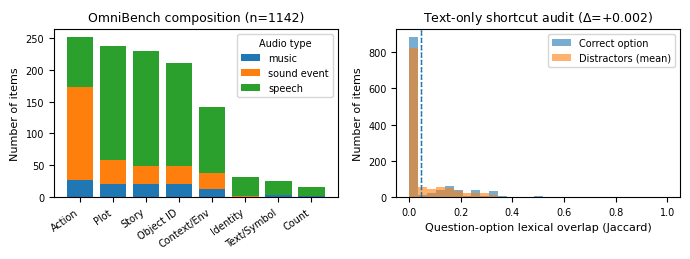

In [11]:
import matplotlib.pyplot as plt

SHORT = {
    "Action and Activity": "Action",
    "Plot Inference": "Plot",
    "Story Description": "Story",
    "Object Identification and Description": "Object ID",
    "Contextual and Environmental Questions": "Context/Env",
    "Identity and Relationship": "Identity",
    "Text and Symbols": "Text/Symbol",
    "Count and Quantity": "Count",
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.0, 2.7))

bottom = np.zeros(len(task_types))
for at in audio_types:
    vals = np.array([grid[t][at] for t in task_types], dtype=float)
    ax1.bar(range(len(task_types)), vals, bottom=bottom, label=at)
    bottom += vals
ax1.set_xticks(range(len(task_types)))
ax1.set_xticklabels([SHORT.get(t, t) for t in task_types],
                    fontsize=7, rotation=35, ha="right")
ax1.set_ylabel("Number of items", fontsize=8)
ax1.set_title(f"OmniBench composition (n={len(records)})", fontsize=9)
ax1.legend(title="Audio type", fontsize=7, title_fontsize=7)

bins = np.linspace(0, max(0.6, float(correct_ov.max())), 30)
ax2.hist(correct_ov, bins=bins, alpha=0.6, label="Correct option")
ax2.hist(distractor_ov, bins=bins, alpha=0.6, label="Distractors (mean)")
ax2.axvline(correct_ov.mean(), linestyle="--", linewidth=1)
ax2.axvline(distractor_ov.mean(), linestyle=":", linewidth=1)
ax2.set_xlabel("Question-option lexical overlap (Jaccard)", fontsize=8)
ax2.set_ylabel("Number of items", fontsize=8)
ax2.set_title(f"Text-only shortcut audit ($\\Delta$={delta:+.3f})", fontsize=9)
ax2.legend(fontsize=7)

for ax in (ax1, ax2):
    ax.tick_params(labelsize=7)
fig.tight_layout()
fig.savefig("omnibench_analysis.pdf")
print("wrote omnibench_analysis.pdf")
plt.show()

## 11. Numbers for the writeup

Everything cited in the preproposal, printed together. If any of these disagree with the `.tex`, the `.tex` is stale.

In [12]:
at = Counter(r["audio type"] for r in records)
print(f"items                : {len(records)}")
print(f"task types           : {len(task_types)}  (repo README says 7)")
print(f"audio types          : {dict(at)}")
print(f"top-5 task coverage  : {top5} / {len(records)}")
print(f"smallest three types : {[sum(grid[t].values()) for t in task_types[-3:]]}")
print(f"overlap correct      : {correct_ov.mean():.4f}")
print(f"overlap distractors  : {distractor_ov.mean():.4f}")
print(f"delta [95% CI]       : {delta:+.4f} [{lo:+.5f}, {hi:+.5f}]")
print(f"max-overlap heuristic: {hits/len(records):.1%} vs 25.0% chance")

items                : 1142
task types           : 8  (repo README says 7)
audio types          : {'speech': 771, 'sound event': 265, 'music': 106}
top-5 task coverage  : 1070 / 1142
smallest three types : [32, 25, 15]
overlap correct      : 0.0460
overlap distractors  : 0.0442
delta [95% CI]       : +0.0019 [-0.00162, +0.00560]
max-overlap heuristic: 26.1% vs 25.0% chance
